<a href="https://colab.research.google.com/github/nirob271/bacterial-species-cnn-comparison/blob/main/DIBaS_CNN_Revision_5fold_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Revision notebook: Efficient Bacterial Species Identification (DIBaS) - 5-fold CV, statistics, new models, deployment analysis

**What this notebook adds compared with the first version** (each item answers reviewer comments):

| New in this notebook | Reviewer comment it answers |
|---|---|
| 5-fold stratified cross-validation (every image is tested exactly once), mean +/- std, 95% CI, pooled bootstrap CI, McNemar + paired-bootstrap tests | R1-3, R2-3, R4 (small test set, single split, no CI) |
| Per-class support / precision / recall / F1 tables, top confusions, same-genus error share | R2 (per-class support), R1 (class-level analysis) |
| Dataset audit: 692 raw vs 689 usable, which files were corrupted, class key with corrected names | R1-4, R2 (consistent counts, class definition) |
| Two newer models (MobileNetV4-Conv-S, ConvNeXt-Tiny) trained with the same protocol | R3 (old models) |
| Training AND validation loss on the same plot | R3 (Fig. 2) |
| Readable Fig. 3 / Fig. 4 (page-width, large fonts, numbered classes) | R3 (Figs. 3 and 4 unreadable) |
| Full environment log (CPU model, threads, GPU, library versions), latency with 20 warm-up / 100 runs x 3 rounds, 1-thread CPU latency, torch FLOP counter | R2 (timing environment) |
| Deployment score: exact formula, normalisation, sensitivity to weights and to GPU vs CPU latency | R2 (score formulation), R2 (tone down claims) |
| Grad-CAM, Grad-CAM++, ScoreCAM on several examples (correct + wrong) and a quantitative faithfulness test | R4 (interpretability) |
| Nearest-neighbour leakage audit (are near-duplicate images shared across folds?) | R2 (specimen-level grouping) |
| Saved splits, config, environment, per-run predictions | R2 (reproducibility) |

**How to run**
1. `Runtime -> Change runtime type -> T4 GPU`.
2. Set the three switches in the second code cell. **First run with `SMOKE_TEST = True`** (about 3-5 min) to check that everything works, then set it to `False` and `Runtime -> Run all`.
3. Everything is resumable: finished folds are saved (to Google Drive if `USE_DRIVE = True`), so after a disconnect just run all cells again.

In [ ]:
!pip install -q thop grad-cam timm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 0. Setup, switches, paths

In [ ]:
import os, sys, io, re, json, time, ssl, shutil, zipfile, random, platform, subprocess, copy, itertools, urllib.request
from pathlib import Path
from importlib import metadata

import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from scipy import stats

# ========================= SWITCHES (edit these) =========================
SMOKE_TEST       = False   # True = 1 model, 1 fold, 1+1 epochs: quick check that the whole notebook runs
USE_DRIVE        = True    # True = keep results on Google Drive (survives a Colab disconnect)
RUN_EXTRA_MODELS = True    # True = also train the newer models (MobileNetV4-Conv-S, ConvNeXt-Tiny)
# =========================================================================

CFG = dict(
    seed          = 42,
    n_splits      = 5,        # k of the stratified k-fold CV
    n_repeats     = 1,        # >1 = repeated CV with different fold assignments (slower)
    val_frac      = 0.15,     # share of each training portion held out (stratified) for early stopping / model selection
    cache_size    = 512,      # long side of the cached images (as in the first version)
    img_size      = 224,
    batch_size    = 32,
    num_workers   = 2,
    head_epochs   = 5,        # stage 1
    head_lr       = 1e-3,
    ft_epochs     = 30,       # stage 2 (max)
    ft_lr         = 1e-4,
    weight_decay  = 1e-4,
    patience      = 5,
    label_smooth  = 0.05,
    amp           = True,
    mnv3_weights  = "IMAGENET1K_V2",   # first version used V2 for MobileNetV3 (V1 for the other two); set "IMAGENET1K_V1" for strict recipe parity
    base_models   = ["mobilenetv3_large", "efficientnet_b0", "resnet18"],
    extra_models  = ["mobilenetv4_conv_small", "convnext_tiny"],
    n_boot        = 2000,
)
if SMOKE_TEST:
    CFG.update(head_epochs=1, ft_epochs=1, base_models=["resnet18"], extra_models=[], n_boot=200)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/dibas_revision")
else:
    BASE = Path("/content/dibas_revision")

RAW_DIR  = Path("/content/dibas/raw")                 # big TIFFs: always local, never on Drive
PROC_DIR = BASE / "processed"                         # 512-px JPEG cache (small)
OUT      = BASE / ("results_smoke" if SMOKE_TEST else "results")
FIG_DIR, TAB_DIR, RUN_DIR, CKPT_DIR = OUT / "figures", OUT / "tables", OUT / "runs", OUT / "checkpoints"
for d in (RAW_DIR, PROC_DIR, FIG_DIR, TAB_DIR, RUN_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

# IEEE figure geometry: single column = 3.5 in, full page width = 7.16 in
COL_W, PAGE_W = 3.5, 7.16
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "figure.dpi": 110,
                     "savefig.dpi": 300, "savefig.bbox": "tight"})
print("device:", DEVICE, "| output folder:", OUT)

Mounted at /content/drive
device: cuda | output folder: /content/drive/MyDrive/dibas_revision/results


In [ ]:
# ---- Environment log (answers: "complete CPU/GPU timing environments") ----
def cpu_model():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.lower().startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or "unknown"

def pkg_version(n):
    try: return metadata.version(n)
    except Exception: return "n/a"

ENV = dict(
    date=time.strftime("%Y-%m-%d %H:%M"), python=platform.python_version(),
    torch=torch.__version__, torchvision=pkg_version("torchvision"), timm=pkg_version("timm"),
    grad_cam=pkg_version("grad-cam"), thop=pkg_version("thop"), scikit_learn=pkg_version("scikit-learn"),
    numpy=np.__version__, cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
    gpu=(torch.cuda.get_device_name(0) if torch.cuda.is_available() else None),
    cpu_model=cpu_model(), cpu_logical_cores=os.cpu_count(),
    torch_cpu_threads=torch.get_num_threads(), ram_gb=round(psutil.virtual_memory().total / 1e9, 1),
)
(OUT / "environment.json").write_text(json.dumps(ENV, indent=2))
(OUT / "lscpu.txt").write_text(subprocess.run(["lscpu"], capture_output=True, text=True).stdout)
print(json.dumps(ENV, indent=2))

{
  "date": "2026-10-30 18:46",
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "timm": "1.0.30",
  "grad_cam": "1.5.7",
  "thop": "0.1.1-2209072238",
  "scikit_learn": "1.6.1",
  "numpy": "2.1.3",
  "cuda": "13.0",
  "cudnn": 92700,
  "gpu": "Tesla T4",
  "cpu_model": "Intel(R) Xeon(R) CPU @ 2.00GHz",
  "cpu_logical_cores": 2,
  "torch_cpu_threads": 1,
  "ram_gb": 13.6
}


## 1. Dataset: download, resize-cache, audit (692 raw -> 689 usable)
The download and cache steps are skipped automatically when the cache and audit table already exist (for example after a disconnect with `USE_DRIVE = True`).

In [ ]:
IMG_EXT  = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}
BASE_URL = "https://doctoral.matinf.uj.edu.pl/database/dibas/"
SPECIES_ZIPS = [
    "Acinetobacter.baumanii", "Actinomyces.israeli", "Bacteroides.fragilis",
    "Bifidobacterium.spp", "Candida.albicans", "Clostridium.perfringens",
    "Enterococcus.faecium", "Enterococcus.faecalis", "Escherichia.coli",
    "Fusobacterium", "Lactobacillus.casei", "Lactobacillus.crispatus",
    "Lactobacillus.delbrueckii", "Lactobacillus.gasseri", "Lactobacillus.jehnsenii",
    "Lactobacillus.johnsonii", "Lactobacillus.paracasei", "Lactobacillus.plantarum",
    "Lactobacillus.reuteri", "Lactobacillus.rhamnosus", "Lactobacillus.salivarius",
    "Listeria.monocytogenes", "Micrococcus.spp", "Neisseria.gonorrhoeae",
    "Porfyromonas.gingivalis", "Propionibacterium.acnes", "Proteus",
    "Pseudomonas.aeruginosa", "Staphylococcus.aureus", "Staphylococcus.epidermidis",
    "Staphylococcus.saprophiticus", "Streptococcus.agalactiae", "Veionella",
]
CTX = ssl._create_unverified_context()   # the source server often fails default certificate checks

def fetch(url, dest, tries=3, timeout=120):
    for t in range(tries):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=timeout, context=CTX) as r, open(dest, "wb") as f:
                shutil.copyfileobj(r, f)
            if dest.stat().st_size > 10_000:
                return True
        except Exception as e:
            print(f"    attempt {t+1}/{tries} failed: {type(e).__name__}: {e}")
            time.sleep(2)
    return False

def download_dibas():
    zip_dir = RAW_DIR.parent / "zips"; zip_dir.mkdir(parents=True, exist_ok=True)
    failed = []
    for i, name in enumerate(SPECIES_ZIPS, 1):
        tdir = RAW_DIR / name
        if tdir.exists() and any(tdir.glob("*")):
            print(f"[{i:2d}/33] {name:32s} already present"); continue
        zpath = zip_dir / f"{name}.zip"
        if not (zpath.exists() and zpath.stat().st_size > 10_000):
            if not fetch(BASE_URL + name + ".zip", zpath):
                failed.append(name); print(f"[{i:2d}/33] {name:32s} DOWNLOAD FAILED"); continue
        try:
            tmp = RAW_DIR.parent / "_tmp"
            if tmp.exists(): shutil.rmtree(tmp)
            tmp.mkdir(parents=True)
            with zipfile.ZipFile(zpath) as zf: zf.extractall(tmp)
            tdir.mkdir(parents=True, exist_ok=True)
            n = 0
            for p in tmp.rglob("*"):
                if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("."):
                    shutil.copy(p, tdir / p.name); n += 1
            shutil.rmtree(tmp)
            print(f"[{i:2d}/33] {name:32s} {n:3d} images")
            if n == 0: failed.append(name)
        except Exception as e:
            failed.append(name); print(f"[{i:2d}/33] {name:32s} EXTRACT FAILED {type(e).__name__}: {e}")
    print("\nfailed species:", failed if failed else "none")
    n_ok = len([d for d in RAW_DIR.iterdir() if d.is_dir() and any(d.glob("*"))])
    assert n_ok >= 30, "Too few classes downloaded - re-run this cell, or upload a pre-downloaded copy."
    return failed

def build_cache(raw_dir, proc_dir, size=512, quality=95):
    """Resize every image once (long side = size) and store as JPEG. Returns the list of files that could not be read."""
    proc_dir.mkdir(parents=True, exist_ok=True)
    failed = []
    for cls_dir in sorted(raw_dir.iterdir()):
        if not cls_dir.is_dir(): continue
        out_cls = proc_dir / cls_dir.name; out_cls.mkdir(parents=True, exist_ok=True)
        for p in sorted(cls_dir.iterdir()):
            if p.suffix.lower() not in IMG_EXT: continue
            out_p = out_cls / (p.stem + ".jpg")
            if out_p.exists(): continue
            try:
                with Image.open(p) as im:
                    im = im.convert("RGB")
                    w, h = im.size; sc = size / max(w, h)
                    if sc < 1: im = im.resize((round(w * sc), round(h * sc)), Image.BICUBIC)
                    im.save(out_p, "JPEG", quality=quality)
            except Exception as e:
                failed.append({"class": cls_dir.name, "file": p.name, "error": f"{type(e).__name__}: {e}"})
                if out_p.exists(): out_p.unlink()
    return failed

In [ ]:
AUDIT_CSV, CORRUPT_CSV = BASE / "dataset_audit.csv", BASE / "corrupted_files.csv"
have_cache = AUDIT_CSV.exists() and any(PROC_DIR.glob("*/*.jpg"))

if have_cache:
    print("Processed cache + audit table found -> skipping download.")
    AUDIT = pd.read_csv(AUDIT_CSV)
    CORRUPT = pd.read_csv(CORRUPT_CSV) if CORRUPT_CSV.exists() else pd.DataFrame(columns=["Folder name", "File", "Error"])
else:
    download_dibas()
    cache_fail = build_cache(RAW_DIR, PROC_DIR, CFG["cache_size"])
    err_map = {(r["class"], r["file"]): r["error"] for r in cache_fail}
    rows, bad = [], []
    for cls_dir in sorted(RAW_DIR.iterdir()):
        if not cls_dir.is_dir(): continue
        raw_files = [p for p in sorted(cls_dir.iterdir()) if p.suffix.lower() in IMG_EXT]
        usable = [p for p in raw_files if (PROC_DIR / cls_dir.name / (p.stem + ".jpg")).exists()]
        rows.append({"Folder name": cls_dir.name, "Raw images": len(raw_files), "Usable images": len(usable),
                     "Excluded (unreadable)": len(raw_files) - len(usable)})
        for p in raw_files:
            if not (PROC_DIR / cls_dir.name / (p.stem + ".jpg")).exists():
                bad.append({"Folder name": cls_dir.name, "File": p.name, "Error": err_map.get((cls_dir.name, p.name), "")})
    AUDIT = pd.DataFrame(rows); CORRUPT = pd.DataFrame(bad, columns=["Folder name", "File", "Error"])
    AUDIT.to_csv(AUDIT_CSV, index=False); CORRUPT.to_csv(CORRUPT_CSV, index=False)

AUDIT.to_csv(TAB_DIR / "table_dataset_audit.csv", index=False)
CORRUPT.to_csv(TAB_DIR / "corrupted_files.csv", index=False)
print(AUDIT.to_string(index=False))
print(f"\nclasses: {len(AUDIT)} | raw: {AUDIT['Raw images'].sum()} | usable: {AUDIT['Usable images'].sum()} | excluded: {AUDIT['Excluded (unreadable)'].sum()}")
print("\nexcluded files:"); print(CORRUPT.to_string(index=False) if len(CORRUPT) else "none recorded")

[ 1/33] Acinetobacter.baumanii            20 images
[ 2/33] Actinomyces.israeli               23 images
[ 3/33] Bacteroides.fragilis              23 images
[ 4/33] Bifidobacterium.spp               23 images
[ 5/33] Candida.albicans                  20 images
[ 6/33] Clostridium.perfringens           23 images
[ 7/33] Enterococcus.faecium              20 images
[ 8/33] Enterococcus.faecalis             20 images
[ 9/33] Escherichia.coli                  20 images
[10/33] Fusobacterium                     23 images
[11/33] Lactobacillus.casei               20 images
[12/33] Lactobacillus.crispatus           20 images
[13/33] Lactobacillus.delbrueckii         20 images
[14/33] Lactobacillus.gasseri             20 images
[15/33] Lactobacillus.jehnsenii           20 images
[16/33] Lactobacillus.johnsonii           20 images
[17/33] Lactobacillus.paracasei           20 images
[18/33] Lactobacillus.plantarum           20 images
[19/33] Lactobacillus.reuteri             20 images
[20/33] Lact

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


                 Folder name  Raw images  Usable images  Excluded (unreadable)
      Acinetobacter.baumanii          20             20                      0
         Actinomyces.israeli          23             23                      0
        Bacteroides.fragilis          23             23                      0
         Bifidobacterium.spp          23             23                      0
            Candida.albicans          20             20                      0
     Clostridium.perfringens          23             23                      0
       Enterococcus.faecalis          20             20                      0
        Enterococcus.faecium          20             20                      0
            Escherichia.coli          20             20                      0
               Fusobacterium          23             23                      0
         Lactobacillus.casei          20             20                      0
     Lactobacillus.crispatus          20            

In [ ]:
# ---- Class list, readable names, dataframe, in-memory image cache ----
# DIBaS folder names contain spelling variants; the display names below use the accepted spelling.
# Keep the folder name as the dataset label and say so in the paper (e.g. "Veionella" in the dataset = Veillonella).
DISPLAY = {
    "Acinetobacter.baumanii": "Acinetobacter baumannii", "Actinomyces.israeli": "Actinomyces israelii",
    "Bifidobacterium.spp": "Bifidobacterium spp.", "Micrococcus.spp": "Micrococcus spp.",
    "Lactobacillus.jehnsenii": "Lactobacillus jensenii", "Porfyromonas.gingivalis": "Porphyromonas gingivalis",
    "Veionella": "Veillonella",
}
records = []
for cls_dir in sorted(PROC_DIR.iterdir()):
    if cls_dir.is_dir():
        for p in sorted(cls_dir.glob("*.jpg")):
            records.append({"path": str(p), "folder": cls_dir.name, "rel": f"{cls_dir.name}/{p.name}"})
df = pd.DataFrame(records)
FOLDERS = sorted(df["folder"].unique())
NUM_CLASSES = len(FOLDERS)
df["label"] = df["folder"].map({f: i for i, f in enumerate(FOLDERS)})
CLASS_NAMES = [DISPLAY.get(f, f.replace(".", " ")) for f in FOLDERS]
GENUS = [n.split()[0] for n in CLASS_NAMES]
PATHS, LABELS = df["path"].tolist(), df["label"].values

CLASS_KEY = pd.DataFrame({"No.": range(1, NUM_CLASSES + 1), "Dataset folder name": FOLDERS,
                          "Species / genus": CLASS_NAMES,
                          "Usable images": df.groupby("label").size().reindex(range(NUM_CLASSES)).values})
CLASS_KEY.to_csv(TAB_DIR / "table_class_key.csv", index=False)
print(CLASS_KEY.to_string(index=False))
print(f"\n{NUM_CLASSES} classes, {len(df)} usable images")

t0 = time.time()
IMG = {p: Image.open(p).convert("RGB") for p in PATHS}      # decoded once, reused every epoch (faster training)
print(f"images loaded into RAM in {time.time()-t0:.1f}s")

 No.          Dataset folder name              Species / genus  Usable images
   1       Acinetobacter.baumanii      Acinetobacter baumannii             20
   2          Actinomyces.israeli         Actinomyces israelii             23
   3         Bacteroides.fragilis         Bacteroides fragilis             23
   4          Bifidobacterium.spp         Bifidobacterium spp.             23
   5             Candida.albicans             Candida albicans             20
   6      Clostridium.perfringens      Clostridium perfringens             23
   7        Enterococcus.faecalis        Enterococcus faecalis             20
   8         Enterococcus.faecium         Enterococcus faecium             20
   9             Escherichia.coli             Escherichia coli             20
  10                Fusobacterium                Fusobacterium             23
  11          Lactobacillus.casei          Lactobacillus casei             20
  12      Lactobacillus.crispatus      Lactobacillus crispatus  

## 2. Stratified 5-fold cross-validation splits (made before any augmentation)
For each fold: the fold is the **test** set (about 20%). The remaining 80% is split again, stratified, into **train** (85%) and **validation** (15%). The validation part is used only for early stopping and checkpoint selection, exactly as in the first version. Every image appears in a test set exactly once.

In [ ]:
from sklearn.model_selection import StratifiedKFold, train_test_split

SPLITS, split_rows = {}, []
for rep in range(CFG["n_repeats"]):
    skf = StratifiedKFold(n_splits=CFG["n_splits"], shuffle=True, random_state=CFG["seed"] + rep)
    for fold, (tv, te) in enumerate(skf.split(df, df["label"])):
        tr, va = train_test_split(tv, test_size=CFG["val_frac"], stratify=df["label"].values[tv],
                                  random_state=CFG["seed"] + 100 * rep + fold)
        tr, va, te = np.sort(tr), np.sort(va), np.sort(te)
        # pairwise disjointness (the first version only checked the triple intersection)
        assert not (set(tr) & set(va)) and not (set(tr) & set(te)) and not (set(va) & set(te))
        assert len(tr) + len(va) + len(te) == len(df)
        assert len(set(df["label"].values[te])) == NUM_CLASSES, "a class is missing from a test fold"
        SPLITS[(rep, fold)] = (tr, va, te)
        for role, idx in (("train", tr), ("val", va), ("test", te)):
            for j in idx:
                split_rows.append({"repeat": rep, "fold": fold, "role": role, "file": df["rel"].iloc[j],
                                   "class": FOLDERS[LABELS[j]]})
pd.DataFrame(split_rows).to_csv(TAB_DIR / "splits.csv", index=False)       # share this file on GitHub
print(pd.DataFrame([{"repeat": r, "fold": f, "train": len(a), "val": len(b), "test": len(c),
                     "min test imgs/class": int(np.bincount(LABELS[c]).min())} for (r, f), (a, b, c) in SPLITS.items()]).to_string(index=False))

 repeat  fold  train  val  test  min test imgs/class
      0     0    468   83   138                    4
      0     1    468   83   138                    4
      0     2    468   83   138                    4
      0     3    468   83   138                    4
      0     4    469   83   137                    4


In [ ]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
S = CFG["img_size"]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.6, 1.0), ratio=(0.85, 1.18)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(), transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),   # saturation = 0.10 (the first-version paper said 0.15)
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(int(S * 1.14)),        # = Resize(255): the SHORTER side becomes 255 px (aspect ratio kept), then centre-crop 224
    transforms.CenterCrop(S),
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class DIBaSDataset(Dataset):
    def __init__(self, idx, transform):
        self.idx, self.transform = list(idx), transform
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.transform(IMG[PATHS[j]]), int(LABELS[j])

def make_loaders(tr, va, te, seed):
    g = torch.Generator(); g.manual_seed(seed)
    kw = dict(num_workers=CFG["num_workers"], pin_memory=True)
    tl = DataLoader(DIBaSDataset(tr, train_tf), batch_size=CFG["batch_size"], shuffle=True, generator=g, **kw)
    vl = DataLoader(DIBaSDataset(va, eval_tf), batch_size=CFG["batch_size"], shuffle=False, **kw)
    tel = DataLoader(DIBaSDataset(te, eval_tf), batch_size=CFG["batch_size"], shuffle=False, **kw) if te is not None else None
    return tl, vl, tel

def denorm(t):
    return (t.cpu() * torch.tensor(IMAGENET_STD).view(3, 1, 1) + torch.tensor(IMAGENET_MEAN).view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).numpy()

## 3. Models
Original three (torchvision, ImageNet-1K weights) plus two newer models from `timm` (explicit ImageNet-1K-only weight tags, so no extra pre-training data sneaks in):
* **MobileNetV4-Conv-Small** (2024, mobile-oriented) - stage 2 unfreezes the last two stage groups.
* **ConvNeXt-Tiny** (2022, modern but heavier, 28M parameters) - stage 2 unfreezes the last stage.

The unfreezing depth is architecture-specific for all five models; say this in the paper.

In [ ]:
import timm
from torchvision.models import (mobilenet_v3_large, MobileNet_V3_Large_Weights, efficientnet_b0, EfficientNet_B0_Weights,
                                resnet18, ResNet18_Weights)

NICE = {"mobilenetv3_large": "MobileNetV3-Large", "efficientnet_b0": "EfficientNet-B0", "resnet18": "ResNet18",
        "mobilenetv4_conv_small": "MobileNetV4-Conv-S", "convnext_tiny": "ConvNeXt-Tiny"}
TIMM_TAGS = {"mobilenetv4_conv_small": "mobilenetv4_conv_small.e2400_r224_in1k", "convnext_tiny": "convnext_tiny.fb_in1k"}

def build_model(name, num_classes=None, pretrained=True):
    """returns (model, head_params, stage2_modules, gradcam_target_layer)"""
    num_classes = num_classes or NUM_CLASSES
    if name == "mobilenetv3_large":
        w = getattr(MobileNet_V3_Large_Weights, CFG["mnv3_weights"]) if pretrained else None
        m = mobilenet_v3_large(weights=w)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
        return m, list(m.classifier.parameters()), [m.features[-4:]], m.features[-1]
    if name == "efficientnet_b0":
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        return m, list(m.classifier.parameters()), [m.features[-3:]], m.features[-1]
    if name == "resnet18":
        m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m, list(m.fc.parameters()), [m.layer4, m.layer3], m.layer4[-1]
    if name == "mobilenetv4_conv_small":
        m = timm.create_model(TIMM_TAGS[name], pretrained=pretrained, num_classes=num_classes)
        extra = [x for x in (getattr(m, "conv_head", None), getattr(m, "norm_head", None)) if isinstance(x, nn.Module)]
        return m, list(m.get_classifier().parameters()), [m.blocks[-2:]] + extra, m.blocks[-1]
    if name == "convnext_tiny":
        m = timm.create_model(TIMM_TAGS[name], pretrained=pretrained, num_classes=num_classes)
        return m, list(m.get_classifier().parameters()), [m.stages[-1], m.head.norm], m.stages[-1]
    raise ValueError(name)

def set_trainable(model, head_params, ft_modules, stage):
    for p in model.parameters(): p.requires_grad = False
    for p in head_params: p.requires_grad = True
    if stage == 2:
        for mod in ft_modules:
            for p in mod.parameters(): p.requires_grad = True
    return sum(p.numel() for p in model.parameters() if p.requires_grad), sum(p.numel() for p in model.parameters())

# make sure the extra models can actually be built here; drop them (with a message) if not
ACTIVE_EXTRA = []
if RUN_EXTRA_MODELS:
    for n in CFG["extra_models"]:
        try:
            _m = build_model(n); ACTIVE_EXTRA.append(n); del _m
        except Exception as e:
            print(f"!! cannot build {n} ({type(e).__name__}: {e}) -> skipped. Try: !pip install -U timm")
MODEL_LIST = CFG["base_models"] + ACTIVE_EXTRA

for n in MODEL_LIST:
    m, hp, fm, _ = build_model(n)
    t1, tot = set_trainable(m, hp, fm, 1); t2, _ = set_trainable(m, hp, fm, 2)
    print(f"{NICE[n]:20s} total {tot/1e6:6.2f}M | stage-1 trainable {t1/1e6:6.3f}M | stage-2 trainable {t2/1e6:6.2f}M")
    del m

model.safetensors: reconstructing file:   0%|          |  0.00B / 15.2MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 145MB/s]


MobileNetV3-Large    total   4.24M | stage-1 trainable  1.272M | stage-2 trainable   3.45M
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 156MB/s]


EfficientNet-B0      total   4.05M | stage-1 trainable  0.042M | stage-2 trainable   3.20M
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 180MB/s]


ResNet18             total  11.19M | stage-1 trainable  0.017M | stage-2 trainable  10.51M
MobileNetV4-Conv-S   total   2.54M | stage-1 trainable  0.042M | stage-2 trainable   2.22M
ConvNeXt-Tiny        total  27.85M | stage-1 trainable  0.025M | stage-2 trainable  15.50M


## 4. Training and evaluation functions (same two-stage protocol as the first version, plus validation loss logging)

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix

AMP_ON = CFG["amp"] and DEVICE.type == "cuda"

@torch.no_grad()
def predict(model, loader):
    model.eval(); outs, ys = [], []
    for x, y in loader:
        with torch.autocast("cuda", enabled=AMP_ON):
            o = model(x.to(DEVICE, non_blocking=True))
        outs.append(o.float().cpu()); ys.append(y)
    return torch.cat(outs), torch.cat(ys)

def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return dict(accuracy=float(accuracy_score(y_true, y_pred)), precision_macro=float(p), recall_macro=float(r),
                f1_macro=float(f), f1_weighted=float(f1_score(y_true, y_pred, average="weighted", zero_division=0)))

def run_stage(model, params, train_loader, val_loader, epochs, lr, patience, tag,
              best_state=None, best_f1=-1.0, history=None, ckpt=None, verbose=True):
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
    crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smooth"])
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ON)
    history = history if history is not None else []
    bad = 0
    for ep in range(1, epochs + 1):
        model.train(); tot, run_loss, correct = 0, 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=AMP_ON):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss += loss.item() * y.size(0); correct += (out.argmax(1) == y).sum().item(); tot += y.size(0)
        sched.step()
        logits, y_true = predict(model, val_loader)
        # validation loss uses the SAME criterion (label-smoothed CE) as the training loss, so the two curves are comparable
        val_loss = float(F.cross_entropy(logits, y_true, label_smoothing=CFG["label_smooth"]))
        m = compute_metrics(y_true.numpy(), logits.argmax(1).numpy())
        history.append(dict(stage=tag, epoch=ep, train_loss=run_loss / tot, train_acc=correct / tot,
                            val_loss=val_loss, val_acc=m["accuracy"], val_f1_macro=m["f1_macro"]))
        if verbose:
            print(f"  [{tag}] ep {ep:02d}/{epochs} train_loss {run_loss/tot:.3f} val_loss {val_loss:.3f} "
                  f"val_acc {m['accuracy']:.3f} val_F1m {m['f1_macro']:.3f}")
        if m["f1_macro"] > best_f1:
            best_f1 = m["f1_macro"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if ckpt: torch.save(best_state, ckpt)
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f"  [{tag}] early stopping at epoch {ep} (best val F1m {best_f1:.4f})")
                break
    return best_state, best_f1, history

def train_run(name, tr_idx, va_idx, seed, ckpt=None, verbose=False):
    set_seed(seed)
    train_loader, val_loader, _ = make_loaders(tr_idx, va_idx, None, seed)
    model, head_params, ft_modules, _ = build_model(name)
    model.to(DEVICE)
    set_trainable(model, head_params, ft_modules, 1)
    params = [p for p in model.parameters() if p.requires_grad]
    best_state, best_f1, hist = run_stage(model, params, train_loader, val_loader, CFG["head_epochs"], CFG["head_lr"],
                                          99, "head", ckpt=ckpt, verbose=verbose)
    set_trainable(model, head_params, ft_modules, 2)
    params = [p for p in model.parameters() if p.requires_grad]
    best_state, best_f1, hist = run_stage(model, params, train_loader, val_loader, CFG["ft_epochs"], CFG["ft_lr"],
                                          CFG["patience"], "finetune", best_state=best_state, best_f1=best_f1,
                                          history=hist, ckpt=ckpt, verbose=verbose)
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_f1

def run_cv(model_list):
    """Train + test every (model, repeat, fold). Finished runs are stored in RUN_DIR and skipped on re-run."""
    t_all = time.time()
    for rep in range(CFG["n_repeats"]):
        for fold in range(CFG["n_splits"]):
            if SMOKE_TEST and fold > 0: break
            tr, va, te = SPLITS[(rep, fold)]
            for name in model_list:
                key = f"{name}_r{rep}_f{fold}"
                if (RUN_DIR / f"run_{key}.json").exists():
                    print(f"[skip] {key} already done"); continue
                print(f"\n===== {NICE[name]} | repeat {rep} | fold {fold} =====")
                t0 = time.time()
                ckpt = CKPT_DIR / f"{key}.pt" if (rep == 0 and fold == 0) else None   # fold-0 weights are kept for Grad-CAM
                model, hist, best_val = train_run(name, tr, va, CFG["seed"] + 1000 * rep + fold, ckpt, verbose=(fold == 0))
                _, _, test_loader = make_loaders(tr, va, te, CFG["seed"])
                logits, y_true = predict(model, test_loader)
                y_pred = logits.argmax(1).numpy()
                met = compute_metrics(y_true.numpy(), y_pred)
                minutes = (time.time() - t0) / 60
                hist.to_csv(RUN_DIR / f"hist_{key}.csv", index=False)
                (RUN_DIR / f"run_{key}.json").write_text(json.dumps(dict(
                    model=name, rep=rep, fold=fold, metrics=met, best_val_f1=float(best_val), train_min=minutes,
                    epochs_run=int(len(hist)), test_idx=[int(i) for i in te], y_true=y_true.tolist(), y_pred=y_pred.tolist())))
                print(f"  TEST acc {met['accuracy']:.4f} | macro-F1 {met['f1_macro']:.4f} | {minutes:.1f} min "
                      f"| total elapsed {(time.time()-t_all)/60:.1f} min")
                del model; torch.cuda.empty_cache()
    print("\nfinished:", [NICE[m] for m in model_list])

## 5. Run the cross-validation
Run the next cell first (the three original models, all folds). Look at the minutes printed for fold 0 to estimate the total time. The second cell trains the two newer models; it can be run later.

In [ ]:
run_cv(CFG["base_models"])


===== MobileNetV3-Large | repeat 0 | fold 0 =====
  [head] ep 01/5 train_loss 2.657 val_loss 3.040 val_acc 0.349 val_F1m 0.271
  [head] ep 02/5 train_loss 1.214 val_loss 2.589 val_acc 0.410 val_F1m 0.336
  [head] ep 03/5 train_loss 0.822 val_loss 2.341 val_acc 0.386 val_F1m 0.327
  [head] ep 04/5 train_loss 0.761 val_loss 2.137 val_acc 0.458 val_F1m 0.394
  [head] ep 05/5 train_loss 0.751 val_loss 1.926 val_acc 0.530 val_F1m 0.453
  [finetune] ep 01/30 train_loss 0.740 val_loss 1.612 val_acc 0.590 val_F1m 0.530
  [finetune] ep 02/30 train_loss 0.690 val_loss 1.355 val_acc 0.723 val_F1m 0.664
  [finetune] ep 03/30 train_loss 0.670 val_loss 1.153 val_acc 0.759 val_F1m 0.727
  [finetune] ep 04/30 train_loss 0.648 val_loss 1.024 val_acc 0.831 val_F1m 0.821
  [finetune] ep 05/30 train_loss 0.613 val_loss 0.897 val_acc 0.880 val_F1m 0.866
  [finetune] ep 06/30 train_loss 0.612 val_loss 0.775 val_acc 0.904 val_F1m 0.887
  [finetune] ep 07/30 train_loss 0.619 val_loss 0.725 val_acc 0.892 val_

In [ ]:
if ACTIVE_EXTRA:
    run_cv(ACTIVE_EXTRA)
else:
    print("no extra models active")


===== MobileNetV4-Conv-S | repeat 0 | fold 0 =====
  [head] ep 01/5 train_loss 4.665 val_loss 4.156 val_acc 0.084 val_F1m 0.049
  [head] ep 02/5 train_loss 3.529 val_loss 3.469 val_acc 0.108 val_F1m 0.072
  [head] ep 03/5 train_loss 3.030 val_loss 3.258 val_acc 0.217 val_F1m 0.172
  [head] ep 04/5 train_loss 2.808 val_loss 3.171 val_acc 0.277 val_F1m 0.241
  [head] ep 05/5 train_loss 2.701 val_loss 3.131 val_acc 0.325 val_F1m 0.279
  [finetune] ep 01/30 train_loss 2.400 val_loss 2.566 val_acc 0.386 val_F1m 0.359
  [finetune] ep 02/30 train_loss 1.787 val_loss 1.976 val_acc 0.518 val_F1m 0.470
  [finetune] ep 03/30 train_loss 1.396 val_loss 1.762 val_acc 0.627 val_F1m 0.578
  [finetune] ep 04/30 train_loss 1.170 val_loss 1.562 val_acc 0.675 val_F1m 0.622
  [finetune] ep 05/30 train_loss 1.090 val_loss 1.395 val_acc 0.675 val_F1m 0.645
  [finetune] ep 06/30 train_loss 1.022 val_loss 1.285 val_acc 0.723 val_F1m 0.671
  [finetune] ep 07/30 train_loss 0.930 val_loss 1.256 val_acc 0.795 val

## 6. Statistics: fold-wise mean +/- std, pooled out-of-fold results with bootstrap CIs, paired tests
* **Fold-wise** numbers: mean +/- std over the 5 test folds (plus a t-based 95% CI). Folds share training data, so this CI is only approximate - say so.
* **Pooled out-of-fold (OOF)** numbers: all 689 images, each predicted once by a model that never saw it. The 95% CI is a percentile bootstrap over images (2000 resamples). The same resamples are used for every model, so differences between models are *paired*.
* **Pairwise tests**: exact McNemar test on per-image correctness (Holm-corrected over all pairs) and a paired bootstrap CI for the macro-F1 difference.

In [ ]:
from scipy.stats import binomtest

def macro_f1_fast(y, p, C):
    """Macro-F1 over classes that occur in y or p (same convention as sklearn's default)."""
    y, p = np.asarray(y), np.asarray(p)
    tp = np.bincount(y[y == p], minlength=C); pc = np.bincount(p, minlength=C); tc = np.bincount(y, minlength=C)
    den = pc + tc
    f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    return float(f1[den > 0].mean())

def acc_fast(y, p): return float((np.asarray(y) == np.asarray(p)).mean())

def t_ci(x, level=0.95):
    x = np.asarray(x, float); n = len(x)
    if n < 2: return (np.nan, np.nan)
    h = stats.t.ppf(0.5 + level / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return (x.mean() - h, x.mean() + h)

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def pm(mean, std, d=2): return f"{mean:.{d}f} +/- {std:.{d}f}"

In [ ]:
EXPECTED = 1 if SMOKE_TEST else CFG["n_splits"] * CFG["n_repeats"]

def load_runs():
    rows, preds = [], {}
    for f in sorted(RUN_DIR.glob("run_*.json")):
        r = json.loads(f.read_text())
        rows.append({"model": r["model"], "rep": r["rep"], "fold": r["fold"], "best_val_f1": r["best_val_f1"],
                     "train_min": r["train_min"], "epochs_run": r["epochs_run"], **r["metrics"]})
        preds.setdefault((r["model"], r["rep"]), []).append(pd.DataFrame({"idx": r["test_idx"], "y": r["y_true"], "p": r["y_pred"]}))
    return pd.DataFrame(rows), {k: pd.concat(v).sort_values("idx").reset_index(drop=True) for k, v in preds.items()}

RUNS, PRED = load_runs()
done = RUNS.groupby("model").size()
COMPLETE = [m for m in MODEL_LIST if done.get(m, 0) >= EXPECTED]
print("models with all folds finished:", [NICE[m] for m in COMPLETE])
assert COMPLETE, "no finished models yet - run the training cells first"

runs_out = RUNS.copy(); runs_out["model"] = runs_out["model"].map(NICE)
runs_out.round(4).to_csv(TAB_DIR / "table_cv_per_fold.csv", index=False)

# ---- pooled out-of-fold predictions (repeat 0), shared bootstrap indices ----
Y0 = PRED[(COMPLETE[0], 0)]["y"].values
N = len(Y0)
for m in COMPLETE:
    assert (PRED[(m, 0)]["idx"].values == PRED[(COMPLETE[0], 0)]["idx"].values).all()
BOOT_IDX = np.random.default_rng(CFG["seed"]).integers(0, N, size=(CFG["n_boot"], N))
BOOT, POOL = {}, {}
for m in COMPLETE:
    y, p = PRED[(m, 0)]["y"].values, PRED[(m, 0)]["p"].values
    POOL[m] = dict(acc=acc_fast(y, p), f1=macro_f1_fast(y, p, NUM_CLASSES))
    BOOT[m] = dict(acc=np.array([acc_fast(y[i], p[i]) for i in BOOT_IDX]),
                   f1=np.array([macro_f1_fast(y[i], p[i], NUM_CLASSES) for i in BOOT_IDX]))

rows = []
for m in COMPLETE:
    r = RUNS[RUNS.model == m]
    row = {"Model": NICE[m], "name": m, "n_runs": len(r)}
    for key, col in (("Acc", "accuracy"), ("Prec", "precision_macro"), ("Rec", "recall_macro"), ("F1", "f1_macro"), ("wF1", "f1_weighted")):
        v = r[col].values * 100
        row[f"{key}_mean"], row[f"{key}_std"] = v.mean(), v.std(ddof=1) if len(v) > 1 else np.nan
    lo, hi = t_ci(r["f1_macro"].values * 100); row["F1_tCI_lo"], row["F1_tCI_hi"] = lo, hi
    row["pooled_acc"], row["pooled_f1"] = POOL[m]["acc"] * 100, POOL[m]["f1"] * 100
    row["pooled_acc_lo"], row["pooled_acc_hi"] = np.percentile(BOOT[m]["acc"], [2.5, 97.5]) * 100
    row["pooled_f1_lo"], row["pooled_f1_hi"] = np.percentile(BOOT[m]["f1"], [2.5, 97.5]) * 100
    rows.append(row)
SUM = pd.DataFrame(rows)
SUM.to_csv(TAB_DIR / "table_cv_summary_numeric.csv", index=False)

paper = pd.DataFrame({
    "Model": SUM["Model"],
    "Acc (%)": [pm(a, b) for a, b in zip(SUM.Acc_mean, SUM.Acc_std)],
    "Prec (%)": [pm(a, b) for a, b in zip(SUM.Prec_mean, SUM.Prec_std)],
    "Rec (%)": [pm(a, b) for a, b in zip(SUM.Rec_mean, SUM.Rec_std)],
    "Macro-F1 (%)": [pm(a, b) for a, b in zip(SUM.F1_mean, SUM.F1_std)],
    "W-F1 (%)": [pm(a, b) for a, b in zip(SUM.wF1_mean, SUM.wF1_std)],
    "Macro-F1 95% CI (t, folds)": [f"[{a:.2f}, {b:.2f}]" for a, b in zip(SUM.F1_tCI_lo, SUM.F1_tCI_hi)],
})
paper.to_csv(TAB_DIR / "table_cv_summary_paper.csv", index=False)
pooled = pd.DataFrame({
    "Model": SUM["Model"],
    "Pooled acc (%) [95% CI]": [f"{a:.2f} [{l:.2f}, {h:.2f}]" for a, l, h in zip(SUM.pooled_acc, SUM.pooled_acc_lo, SUM.pooled_acc_hi)],
    "Pooled macro-F1 (%) [95% CI]": [f"{a:.2f} [{l:.2f}, {h:.2f}]" for a, l, h in zip(SUM.pooled_f1, SUM.pooled_f1_lo, SUM.pooled_f1_hi)],
})
pooled.to_csv(TAB_DIR / "table_pooled_oof.csv", index=False)
print("Per-fold results (mean +/- std over folds)\n"); print(paper.to_string(index=False))
print("\nPooled out-of-fold results with bootstrap CIs\n"); print(pooled.to_string(index=False))

# ---- pairwise tests ----
prow = []
for a, b in itertools.combinations(COMPLETE, 2):
    ya, pa, pb = PRED[(a, 0)]["y"].values, PRED[(a, 0)]["p"].values, PRED[(b, 0)]["p"].values
    ca, cb = (ya == pa), (ya == pb)
    n_a_only, n_b_only = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p_mc = binomtest(min(n_a_only, n_b_only), n_a_only + n_b_only, 0.5).pvalue if (n_a_only + n_b_only) > 0 else 1.0
    d = (BOOT[a]["f1"] - BOOT[b]["f1"]) * 100; lo, hi = np.percentile(d, [2.5, 97.5])
    prow.append({"Model A": NICE[a], "Model B": NICE[b], "A-only correct": n_a_only, "B-only correct": n_b_only,
                 "McNemar p": p_mc, "dMacro-F1 (A-B, pp)": (POOL[a]["f1"] - POOL[b]["f1"]) * 100,
                 "95% CI low": lo, "95% CI high": hi})
PAIRS = pd.DataFrame(prow)
if len(PAIRS):
    PAIRS["McNemar p (Holm)"] = holm(PAIRS["McNemar p"].values)
    PAIRS["CI excludes 0"] = (PAIRS["95% CI low"] > 0) | (PAIRS["95% CI high"] < 0)
    PAIRS.round(4).to_csv(TAB_DIR / "table_pairwise_tests.csv", index=False)
    print("\nPairwise comparisons (pooled out-of-fold predictions)\n"); print(PAIRS.round(4).to_string(index=False))

models with all folds finished: ['MobileNetV3-Large', 'EfficientNet-B0', 'ResNet18', 'MobileNetV4-Conv-S', 'ConvNeXt-Tiny']
Per-fold results (mean +/- std over folds)

             Model        Acc (%)       Prec (%)        Rec (%)   Macro-F1 (%)       W-F1 (%) Macro-F1 95% CI (t, folds)
 MobileNetV3-Large 92.89 +/- 3.56 93.56 +/- 4.46 92.79 +/- 3.66 92.38 +/- 4.18 92.52 +/- 4.03             [87.19, 97.57]
   EfficientNet-B0 90.86 +/- 2.14 92.40 +/- 1.71 90.76 +/- 1.95 90.26 +/- 2.12 90.41 +/- 2.25             [87.63, 92.89]
          ResNet18 93.62 +/- 5.69 94.79 +/- 4.88 93.52 +/- 5.80 93.41 +/- 5.84 93.55 +/- 5.74            [86.16, 100.66]
MobileNetV4-Conv-S 84.34 +/- 7.06 86.82 +/- 5.06 84.33 +/- 7.07 83.26 +/- 7.36 83.39 +/- 7.31             [74.12, 92.40]
     ConvNeXt-Tiny 91.44 +/- 0.95 92.06 +/- 1.12 91.45 +/- 0.93 90.64 +/- 0.76 90.74 +/- 0.77             [89.70, 91.58]

Pooled out-of-fold results with bootstrap CIs

             Model Pooled acc (%) [95% CI] Pooled macro-F1

## 7. Per-class results, class key, top confusions, same-genus errors

Per-class F1 (%) from pooled out-of-fold predictions

 No.                        Class  Support (test images)  F1 MobileNetV3-Large  F1 EfficientNet-B0  F1 ResNet18  F1 MobileNetV4-Conv-S  F1 ConvNeXt-Tiny
   1      Acinetobacter baumannii                     20                  83.3                95.0         88.4                   82.6              92.3
   2         Actinomyces israelii                     23                  97.9                95.8         95.8                   93.6              95.7
   3         Bacteroides fragilis                     23                  90.5                85.0         93.0                   82.1              82.1
   4         Bifidobacterium spp.                     23                  97.8                95.7         93.0                   90.9             100.0
   5             Candida albicans                     20                 100.0               100.0        100.0                  100.0             100.0
   6      Clostridium perfri

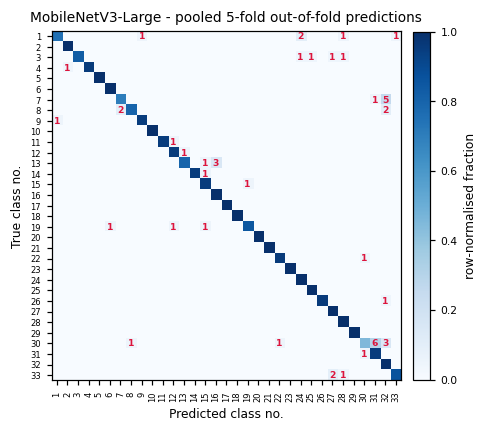

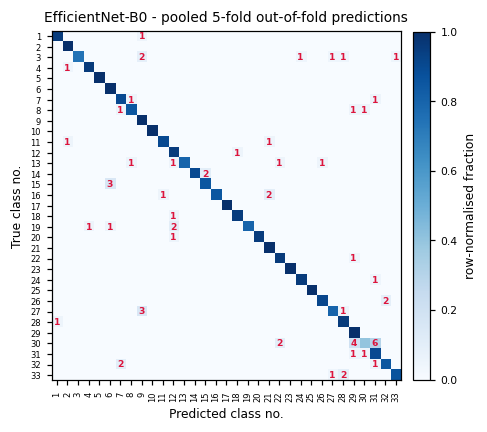

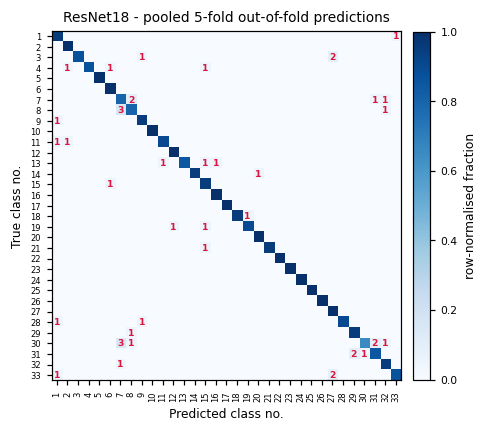

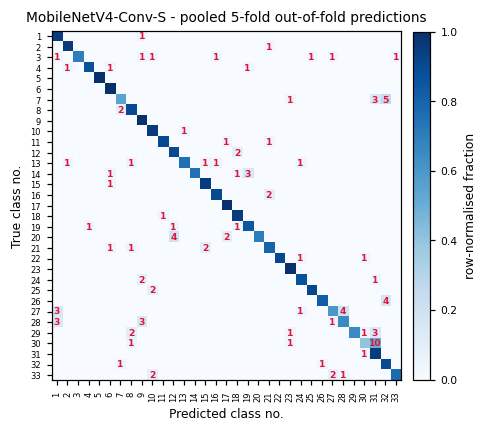

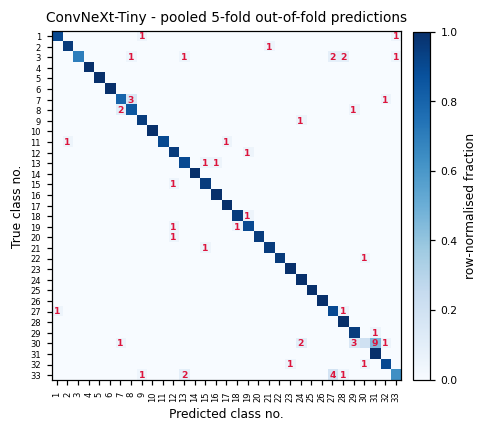

In [ ]:
C = NUM_CLASSES
PER_CLASS = {}
for m in COMPLETE:
    y, p = PRED[(m, 0)]["y"].values, PRED[(m, 0)]["p"].values
    P, R, Fm, Sup = precision_recall_fscore_support(y, p, labels=list(range(C)), zero_division=0)
    PER_CLASS[m] = pd.DataFrame({"No.": range(1, C + 1), "Class": CLASS_NAMES, "Support": Sup,
                                 "Precision": P, "Recall": R, "F1": Fm})
    PER_CLASS[m].round(4).to_csv(TAB_DIR / f"table_per_class_{m}.csv", index=False)
wide = pd.DataFrame({"No.": range(1, C + 1), "Class": CLASS_NAMES, "Support (test images)": PER_CLASS[COMPLETE[0]]["Support"]})
for m in COMPLETE: wide[f"F1 {NICE[m]}"] = (PER_CLASS[m]["F1"] * 100).round(1)
wide.to_csv(TAB_DIR / "table_per_class_f1_wide.csv", index=False)
print("Per-class F1 (%) from pooled out-of-fold predictions\n"); print(wide.to_string(index=False))

# ---- top confusions and same-genus share of the errors ----
conf_rows, genus_rows = [], []
for m in COMPLETE:
    y, p = PRED[(m, 0)]["y"].values, PRED[(m, 0)]["p"].values
    cm = confusion_matrix(y, p, labels=list(range(C)))
    off = cm.copy(); np.fill_diagonal(off, 0)
    n_err = int(off.sum())
    same_genus = int(sum(off[i, j] for i in range(C) for j in range(C) if i != j and GENUS[i] == GENUS[j]))
    genus_rows.append({"Model": NICE[m], "Errors": n_err, "Errors within same genus": same_genus,
                       "Share (%)": round(100 * same_genus / n_err, 1) if n_err else np.nan})
    for i, j in zip(*np.nonzero(off)):
        conf_rows.append({"Model": NICE[m], "True": CLASS_NAMES[i], "Predicted": CLASS_NAMES[j], "Count": int(off[i, j])})
CONF = pd.DataFrame(conf_rows).sort_values(["Model", "Count"], ascending=[True, False])
CONF.groupby("Model").head(10).to_csv(TAB_DIR / "table_top_confusions.csv", index=False)
GEN = pd.DataFrame(genus_rows); GEN.to_csv(TAB_DIR / "table_same_genus_errors.csv", index=False)
print("\nTop confused pairs (pooled OOF)\n"); print(CONF.groupby("Model").head(6).to_string(index=False))
print("\nShare of errors that stay inside one genus\n"); print(GEN.to_string(index=False))

# ---- confusion matrices: numbered axes (class key = table_class_key.csv), off-diagonal counts written in red ----
def plot_cm(m):
    y, p = PRED[(m, 0)]["y"].values, PRED[(m, 0)]["p"].values
    cm = confusion_matrix(y, p, labels=list(range(C)))
    norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(PAGE_W * 0.62, PAGE_W * 0.58))
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    off = cm.copy(); np.fill_diagonal(off, 0)
    for i, j in zip(*np.nonzero(off)):
        ax.text(j, i, int(off[i, j]), ha="center", va="center", fontsize=6, color="crimson", fontweight="bold")
    ticks = np.arange(C)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels(ticks + 1, fontsize=5.5, rotation=90); ax.set_yticklabels(ticks + 1, fontsize=5.5)
    ax.set_xlabel("Predicted class no."); ax.set_ylabel("True class no.")
    ax.set_title(f"{NICE[m]} - pooled 5-fold out-of-fold predictions")
    cb = fig.colorbar(im, fraction=0.046, pad=0.03); cb.set_label("row-normalised fraction")
    fig.savefig(FIG_DIR / f"fig_confusion_{m}.png"); plt.show()
for m in COMPLETE: plot_cm(m)

## 8. Training curves: train loss and validation loss on the same axes (fold 0)
Top row: training vs validation loss (same label-smoothed criterion). Bottom row: validation macro-F1. The dotted line marks the start of stage 2. Training loss is a running average with augmentation in train mode; validation loss is computed in eval mode, so a gap is expected - look for a validation loss that rises while the training loss keeps falling (overfitting).

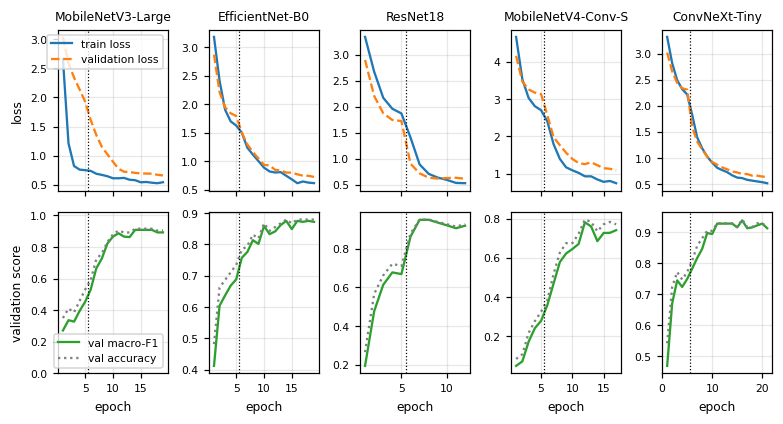

In [ ]:
def load_hist(m, rep=0, fold=0):
    f = RUN_DIR / f"hist_{m}_r{rep}_f{fold}.csv"
    return pd.read_csv(f) if f.exists() else None

n = len(COMPLETE)
fig, axes = plt.subplots(2, n, figsize=(PAGE_W, 3.9), sharex="col", squeeze=False)
for c, m in enumerate(COMPLETE):
    h = load_hist(m)
    if h is None: continue
    x = np.arange(1, len(h) + 1)
    axes[0, c].plot(x, h["train_loss"], label="train loss"); axes[0, c].plot(x, h["val_loss"], "--", label="validation loss")
    axes[1, c].plot(x, h["val_f1_macro"], color="tab:green", label="val macro-F1")
    axes[1, c].plot(x, h["val_acc"], ":", color="tab:gray", label="val accuracy")
    n_head = int((h["stage"] == "head").sum())
    for r in (0, 1): axes[r, c].axvline(n_head + 0.5, color="k", ls=":", lw=0.8)
    axes[0, c].set_title(NICE[m], fontsize=8); axes[1, c].set_xlabel("epoch")
    for r in (0, 1): axes[r, c].grid(alpha=.3)
axes[0, 0].set_ylabel("loss"); axes[1, 0].set_ylabel("validation score"); axes[1, 0].set_ylim(0, 1.02)
axes[0, 0].legend(loc="upper right"); axes[1, 0].legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_training_curves.png"); plt.show()

## 9. Resource profile: parameters, GMac, serialized size, latency
* Latency is **batch size 1, 224x224**, `torch.inference_mode`, 20 warm-up passes then 100 timed passes, repeated in 3 rounds (300 timed passes per setting). On GPU every call is synchronised, so this is true per-image latency.
* Three settings: GPU, CPU with the default thread count, and CPU with **1 thread** (a closer proxy for a small edge device).
* GMac is reported twice: `thop` (as in the first version) and PyTorch's built-in FLOP counter (cross-check; conv/matmul only, MACs = FLOPs / 2). Pick one for the paper and state it.
* Size is the **serialized** `state_dict` (what you would actually ship), in MB = 1024^2 bytes. The first version measured in-memory parameter+buffer bytes, so numbers differ very slightly.
* Latency numbers will not exactly match the first version (different timing method and possibly a different Colab CPU). Use the new ones everywhere in the paper.

In [ ]:
from thop import profile as thop_profile
from torch.utils.flop_counter import FlopCounterMode

@torch.inference_mode()
def measure_latency(model, device, threads=None, n_warmup=20, n_runs=100, rounds=3):
    model = model.to(device).eval()
    x = torch.randn(1, 3, S, S, device=device)
    old = torch.get_num_threads()
    if device.type == "cpu" and threads: torch.set_num_threads(threads)
    times = []
    try:
        for _ in range(rounds):
            for _ in range(n_warmup): model(x)
            if device.type == "cuda": torch.cuda.synchronize()
            for _ in range(n_runs):
                t0 = time.perf_counter(); model(x)
                if device.type == "cuda": torch.cuda.synchronize()
                times.append((time.perf_counter() - t0) * 1000)
    finally:
        torch.set_num_threads(old)
    t = np.array(times)
    return dict(median=float(np.median(t)), mean=float(t.mean()), std=float(t.std()), p95=float(np.percentile(t, 95)))

DEF_THREADS = torch.get_num_threads()
rows = []
for name in MODEL_LIST:
    m = build_model(name, pretrained=False)[0].eval()
    x1 = torch.randn(1, 3, S, S)
    params = sum(p.numel() for p in m.parameters())
    try: thop_macs = thop_profile(copy.deepcopy(m), inputs=(x1,), verbose=False)[0]
    except Exception as e: thop_macs = float("nan"); print("thop failed for", name, e)
    with torch.no_grad(), FlopCounterMode(display=False) as fc: m(x1)
    torch_macs = fc.get_total_flops() / 2
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); size_mb = buf.tell() / 1024 ** 2
    cpu_d = measure_latency(m, torch.device("cpu"))
    cpu_1 = measure_latency(m, torch.device("cpu"), threads=1)
    gpu_d = measure_latency(m, DEVICE) if DEVICE.type == "cuda" else dict(median=np.nan, mean=np.nan, std=np.nan, p95=np.nan)
    rows.append({"name": name, "Model": NICE[name], "Params (M)": params / 1e6, "GMac (thop)": thop_macs / 1e9,
                 "GMac (torch)": torch_macs / 1e9, "Size (MB)": size_mb,
                 "GPU ms": gpu_d["median"], "GPU std": gpu_d["std"],
                 "CPU ms": cpu_d["median"], "CPU std": cpu_d["std"],
                 "CPU 1-thread ms": cpu_1["median"], "CPU 1-thread std": cpu_1["std"]})
    del m
RES = pd.DataFrame(rows)
RES.round(3).to_csv(TAB_DIR / "table_resource_profile.csv", index=False)
print(f"CPU: {ENV['cpu_model']} | default torch threads = {DEF_THREADS} | GPU: {ENV['gpu']}\n")
print(RES.drop(columns="name").round(3).to_string(index=False))

CPU: Intel(R) Xeon(R) CPU @ 2.00GHz | default torch threads = 1 | GPU: Tesla T4

             Model  Params (M)  GMac (thop)  GMac (torch)  Size (MB)  GPU ms  GPU std  CPU ms  CPU std  CPU 1-thread ms  CPU 1-thread std
 MobileNetV3-Large       4.244        0.234         0.215     16.382   5.800    0.787  19.646    2.761           19.612             3.308
   EfficientNet-B0       4.050        0.414         0.385     15.728   7.728    1.158  33.372    4.067           33.990             3.365
          ResNet18      11.193        1.824         1.814     42.773   3.128    0.465  55.816    4.188           55.450             4.939
MobileNetV4-Conv-S       2.535        0.185         0.185      9.861   4.687    0.991  13.440    2.229           13.258             2.037
     ConvNeXt-Tiny      27.846        4.455         4.455    106.286   5.613    0.727 116.910    7.922          117.871             7.811


## 10. Accuracy-efficiency figures and the deployment score
**Score definition (use exactly this in the paper).** For a set of models, with `F1` the (fraction-scale) mean cross-validated macro-F1 and, for each resource metric `x` in {parameters, serialized size, CPU latency}:

`norm(x) = (max(x) - x) / (max(x) - min(x))`  (1 for the cheapest model, 0 for the most expensive in the compared set)

`Score = 0.4 * F1 + 0.2 * norm(Params) + 0.2 * norm(Size) + 0.2 * norm(CPU latency)`

`F1` enters **un-normalised** (this reproduces the 0.9677 / 0.9174 / 0.3780 of the first version). Because only CPU latency is in the score, it favours models that are fast on CPU - the sensitivity table below shows what happens when GPU latency or other weights are used. The score depends on which models are compared (min/max change), so it is computed for the original three models and for all models.

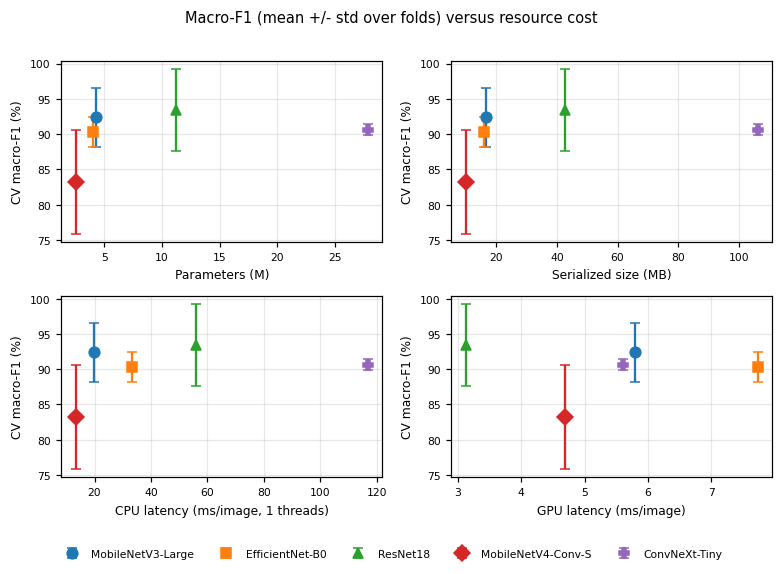

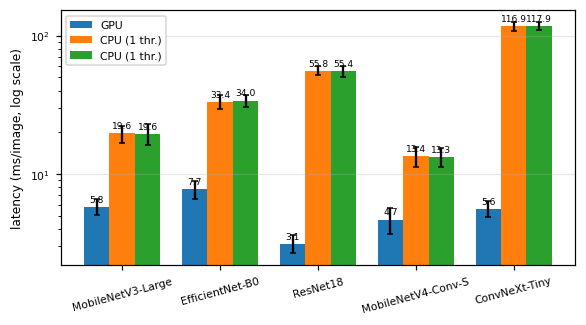

Deployment score - original three models (variant A = the paper's Table V)

            Model  A. Paper: .4 F1 + .2 Params + .2 Size + .2 CPU-lat  B. GPU latency instead of CPU latency  C. 1-thread CPU latency instead of CPU latency  D. CPU and GPU latency (.1 each)  E. Add GMac: .4 F1, .15 each Params/GMac/Size/CPU  F. Accuracy-heavy: .6 F1, .133 each resource  G. Efficiency-heavy: .2 F1, .267 each resource  H. Paper weights but F1 min-max normalised
MobileNetV3-Large                                              0.9592                                 0.8430                                          0.9592                            0.9011                                             0.9618                                        0.9474                                          0.9710                                      0.8584
  EfficientNet-B0                                              0.8851                                 0.7610                                          0.8808        

In [ ]:
MK = {"MobileNetV3-Large": ("o", "tab:blue"), "EfficientNet-B0": ("s", "tab:orange"), "ResNet18": ("^", "tab:green"),
      "MobileNetV4-Conv-S": ("D", "tab:red"), "ConvNeXt-Tiny": ("P", "tab:purple")}
T = SUM[["name", "Model", "F1_mean", "F1_std"]].merge(RES, on=["name", "Model"])
T["f1"] = T["F1_mean"] / 100

# ---- Fig. 3: macro-F1 vs resources (2x2, page width, legend instead of overlapping labels) ----
panels = [("Params (M)", "Parameters (M)"), ("Size (MB)", "Serialized size (MB)"),
          ("CPU ms", f"CPU latency (ms/image, {DEF_THREADS} threads)"), ("GPU ms", "GPU latency (ms/image)")]
fig, axes = plt.subplots(2, 2, figsize=(PAGE_W, 5.0))
for ax, (col, lab) in zip(axes.ravel(), panels):
    for _, r in T.iterrows():
        mk, cl = MK.get(r["Model"], ("o", "k"))
        ax.errorbar(r[col], r["F1_mean"], yerr=r["F1_std"], fmt=mk, color=cl, ms=7, capsize=3, label=r["Model"])
    ax.set_xlabel(lab); ax.set_ylabel("CV macro-F1 (%)"); ax.grid(alpha=.3)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(l), frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Macro-F1 (mean +/- std over folds) versus resource cost", y=0.995)
fig.tight_layout(rect=(0, 0.05, 1, 0.98)); fig.savefig(FIG_DIR / "fig_accuracy_vs_resources.png"); plt.show()

# ---- latency bars: shows the GPU/CPU ordering reversal ----
fig, ax = plt.subplots(figsize=(PAGE_W * 0.75, 3.0))
wd = 0.26; xs = np.arange(len(RES))
for k, (col, lab) in enumerate([("GPU ms", "GPU"), ("CPU ms", f"CPU ({DEF_THREADS} thr.)"), ("CPU 1-thread ms", "CPU (1 thr.)")]):
    b = ax.bar(xs + (k - 1) * wd, RES[col], wd, yerr=RES[col.replace(" ms", " std")], capsize=2, label=lab)
    for rect, v in zip(b, RES[col]): ax.text(rect.get_x() + rect.get_width() / 2, v * 1.08, f"{v:.1f}", ha="center", fontsize=6)
ax.set_xticks(xs); ax.set_xticklabels(RES["Model"], rotation=15); ax.set_yscale("log"); ax.set_ylabel("latency (ms/image, log scale)")
ax.legend(); ax.grid(alpha=.3, axis="y"); fig.tight_layout(); fig.savefig(FIG_DIR / "fig_latency_bars.png"); plt.show()

# ---- deployment score + sensitivity ----
def lower_better(s): r = s.max() - s.min(); return pd.Series(1.0, index=s.index) if r == 0 else (s.max() - s) / r
def higher_better(s): r = s.max() - s.min(); return pd.Series(1.0, index=s.index) if r == 0 else (s - s.min()) / r

def deploy_score(tab, weights, f1_norm=False):
    sc = 0
    for col, w in weights.items():
        if col == "f1": sc = sc + w * (higher_better(tab["f1"]) if f1_norm else tab["f1"])
        else: sc = sc + w * lower_better(tab[col])
    return sc

VARIANTS = {
    "A. Paper: .4 F1 + .2 Params + .2 Size + .2 CPU-lat":        ({"f1": .4, "Params (M)": .2, "Size (MB)": .2, "CPU ms": .2}, False),
    "B. GPU latency instead of CPU latency":                      ({"f1": .4, "Params (M)": .2, "Size (MB)": .2, "GPU ms": .2}, False),
    "C. 1-thread CPU latency instead of CPU latency":             ({"f1": .4, "Params (M)": .2, "Size (MB)": .2, "CPU 1-thread ms": .2}, False),
    "D. CPU and GPU latency (.1 each)":                           ({"f1": .4, "Params (M)": .2, "Size (MB)": .2, "CPU ms": .1, "GPU ms": .1}, False),
    "E. Add GMac: .4 F1, .15 each Params/GMac/Size/CPU":          ({"f1": .4, "Params (M)": .15, "GMac (torch)": .15, "Size (MB)": .15, "CPU ms": .15}, False),
    "F. Accuracy-heavy: .6 F1, .133 each resource":               ({"f1": .6, "Params (M)": .1333, "Size (MB)": .1333, "CPU ms": .1334}, False),
    "G. Efficiency-heavy: .2 F1, .267 each resource":             ({"f1": .2, "Params (M)": .2667, "Size (MB)": .2667, "CPU ms": .2666}, False),
    "H. Paper weights but F1 min-max normalised":                 ({"f1": .4, "Params (M)": .2, "Size (MB)": .2, "CPU ms": .2}, True),
}
def score_block(models):
    sub = T[T["name"].isin(models)].reset_index(drop=True)
    out = pd.DataFrame({"Model": sub["Model"]})
    for k, (w, fn) in VARIANTS.items(): out[k] = deploy_score(sub, w, fn).round(4)
    return out

SC_BASE = score_block(CFG["base_models"]) if all(m in COMPLETE for m in CFG["base_models"]) else None
SC_ALL = score_block(COMPLETE)
if SC_BASE is not None:
    SC_BASE.to_csv(TAB_DIR / "table_deployment_score_base3.csv", index=False)
    print("Deployment score - original three models (variant A = the paper's Table V)\n"); print(SC_BASE.to_string(index=False))
SC_ALL.to_csv(TAB_DIR / "table_deployment_score_all_models.csv", index=False)
print("\nDeployment score - all finished models\n"); print(SC_ALL.to_string(index=False))
RANKS = SC_ALL.set_index("Model").rank(ascending=False).astype(int)
RANKS.to_csv(TAB_DIR / "table_deployment_rank_sensitivity.csv")
print("\nRank of each model under each variant (1 = best)\n"); print(RANKS.T.to_string())

## 11. Interpretability: Grad-CAM, Grad-CAM++, ScoreCAM (fold-0 models)
* **Grad-CAM** weights the last-block feature maps by the spatially averaged gradient of the class score; **Grad-CAM++** uses higher-order gradient terms so several instances/regions of the same class are weighted better; **ScoreCAM** needs no gradients - it measures how much the class score increases when the image is masked by each feature map.
* All maps explain the model's **predicted** class. Examples are chosen automatically: images every model classifies correctly, and images at least one model gets wrong.
* The last cell of this section is a quantitative check: remove the 20% most salient pixels and measure how much the predicted-class probability falls, compared with removing the 20% most salient pixels of a *different* image's map (mismatched-map baseline).

correct-for-all examples: ['Acinetobacter baumannii', 'Escherichia coli', 'Lactobacillus rhamnosus']
error examples          : ['Staphylococcus epidermidis', 'Bacteroides fragilis', 'Bifidobacterium spp.']


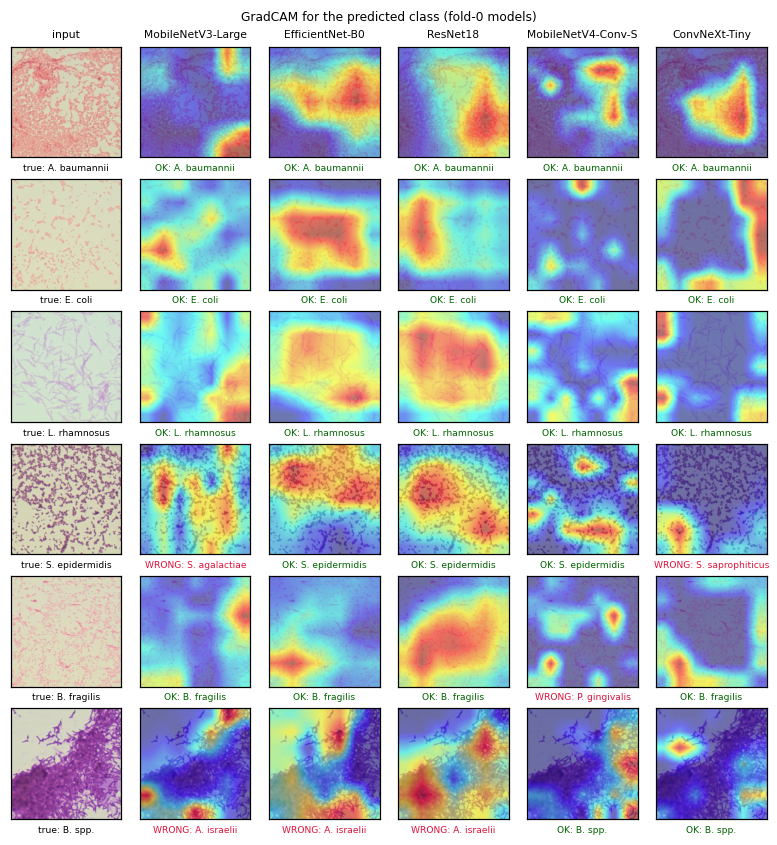

100%|██████████| 32/32 [00:00<00:00, 37.16it/s]


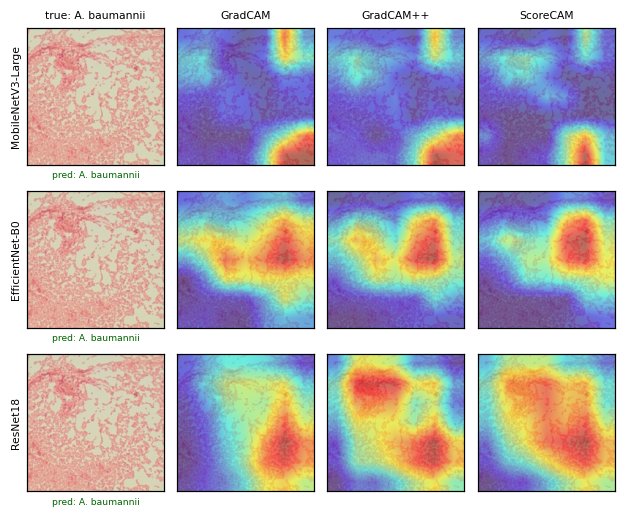

100%|██████████| 32/32 [00:00<00:00, 58.90it/s]


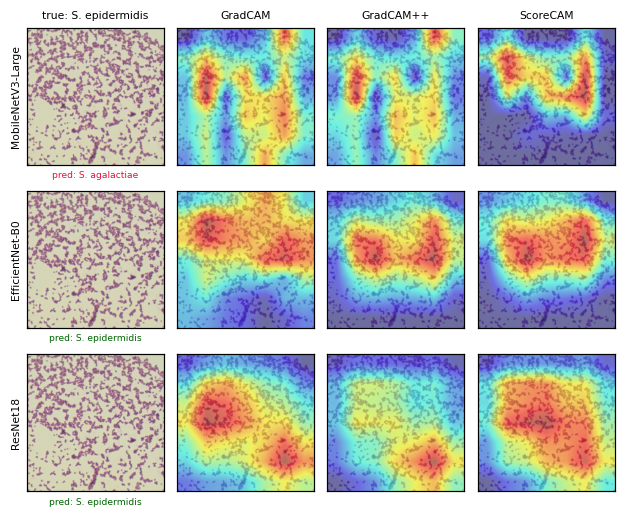

In [ ]:
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, ScoreCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

CAM_CLS = {"GradCAM": GradCAM, "GradCAM++": GradCAMPlusPlus, "ScoreCAM": ScoreCAM}

def load_trained(name):
    m, _, _, layer = build_model(name, pretrained=False)
    m.load_state_dict(torch.load(CKPT_DIR / f"{name}_r0_f0.pt", map_location="cpu"))
    return m.to(DEVICE).eval(), layer

def cam_maps(model, layer, x, class_ids, method):
    with CAM_CLS[method](model=model, target_layers=[layer]) as cam:
        return cam(input_tensor=x, targets=[ClassifierOutputTarget(int(c)) for c in class_ids])   # (B,H,W) in [0,1]

def short(n):
    t = n.split(); return n if len(t) < 2 else f"{t[0][0]}. {' '.join(t[1:])}"

def pick_examples(models, n_ok=3, n_err=3, seed=7):
    te0 = SPLITS[(0, 0)][2]
    P = {m: PRED[(m, 0)].set_index("idx")["p"] for m in models}
    ok, err = [], []
    for j in te0:
        (ok if all(int(P[m].loc[j]) == int(LABELS[j]) for m in models) else err).append(int(j))
    rng = np.random.default_rng(seed)
    def distinct(pool, k):
        pool = list(rng.permutation(pool)); used, out = set(), []
        for j in pool:
            if LABELS[j] not in used: out.append(int(j)); used.add(LABELS[j])
            if len(out) == k: break
        return out
    return distinct(ok, n_ok), distinct(err, n_err)

CAM_MODELS = [m for m in COMPLETE if (CKPT_DIR / f"{m}_r0_f0.pt").exists()]
LOADED = {m: load_trained(m) for m in CAM_MODELS}
ok_ex, err_ex = pick_examples(CAM_MODELS)
print("correct-for-all examples:", [CLASS_NAMES[LABELS[j]] for j in ok_ex])
print("error examples          :", [CLASS_NAMES[LABELS[j]] for j in err_ex])

def cam_grid(examples, method="GradCAM", fname="fig_gradcam_grid.png"):
    nR, nC = len(examples), 1 + len(CAM_MODELS)
    fig, axes = plt.subplots(nR, nC, figsize=(PAGE_W, PAGE_W / nC * nR * 1.08), squeeze=False)
    for r, j in enumerate(examples):
        x = eval_tf(IMG[PATHS[j]]).unsqueeze(0).to(DEVICE); rgb = denorm(x[0]).astype(np.float32)
        axes[r, 0].imshow(rgb); axes[r, 0].set_xlabel(f"true: {short(CLASS_NAMES[LABELS[j]])}", fontsize=6)
        for c, m in enumerate(CAM_MODELS, 1):
            model, layer = LOADED[m]
            with torch.no_grad(): pred = int(model(x).argmax(1))
            cam = cam_maps(model, layer, x, [pred], method)[0]
            axes[r, c].imshow(show_cam_on_image(rgb, cam, use_rgb=True))
            axes[r, c].set_xlabel(("OK: " if pred == LABELS[j] else "WRONG: ") + short(CLASS_NAMES[pred]), fontsize=6,
                                  color="darkgreen" if pred == LABELS[j] else "crimson")
    for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
    axes[0, 0].set_title("input", fontsize=7)
    for c, m in enumerate(CAM_MODELS, 1): axes[0, c].set_title(NICE[m], fontsize=7)
    fig.suptitle(f"{method} for the predicted class (fold-0 models)", fontsize=8)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()

cam_grid(ok_ex + err_ex, "GradCAM", "fig_gradcam_grid.png")

# method comparison for one correct and one wrongly classified example (base models only)
def method_compare(j, tag):
    models = [m for m in CAM_MODELS if m in CFG["base_models"]]
    meths = ["GradCAM", "GradCAM++", "ScoreCAM"]
    fig, axes = plt.subplots(len(models), 1 + len(meths), figsize=(PAGE_W * 0.8, PAGE_W * 0.8 / (1 + len(meths)) * len(models) * 1.1), squeeze=False)
    x = eval_tf(IMG[PATHS[j]]).unsqueeze(0).to(DEVICE); rgb = denorm(x[0]).astype(np.float32)
    for r, m in enumerate(models):
        model, layer = LOADED[m]
        with torch.no_grad(): pred = int(model(x).argmax(1))
        axes[r, 0].imshow(rgb); axes[r, 0].set_ylabel(NICE[m], fontsize=7)
        axes[r, 0].set_xlabel(f"pred: {short(CLASS_NAMES[pred])}", fontsize=6, color="darkgreen" if pred == LABELS[j] else "crimson")
        for c, meth in enumerate(meths, 1):
            cam = cam_maps(model, layer, x, [pred], meth)[0]
            axes[r, c].imshow(show_cam_on_image(rgb, cam, use_rgb=True))
            if r == 0: axes[r, c].set_title(meth, fontsize=7)
    axes[0, 0].set_title(f"true: {short(CLASS_NAMES[LABELS[j]])}", fontsize=7)
    for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(); fig.savefig(FIG_DIR / f"fig_cam_methods_{tag}.png"); plt.show()

if ok_ex: method_compare(ok_ex[0], "correct")
if err_ex: method_compare(err_ex[0], "error")

In [ ]:
# ---- quantitative faithfulness: delete the top-20% salient pixels, measure the drop in predicted-class probability ----
def cam_faithfulness(name, frac=0.2, methods=("GradCAM", "GradCAM++"), bs=16):
    model, layer = LOADED[name]
    te = SPLITS[(0, 0)][2]
    X = torch.stack([eval_tf(IMG[PATHS[j]]) for j in te])
    with torch.no_grad():
        P0 = torch.cat([model(X[i:i + bs].to(DEVICE)).float().softmax(1).cpu() for i in range(0, len(X), bs)])
    pred = P0.argmax(1); p0 = P0.gather(1, pred[:, None])[:, 0]
    H, W = X.shape[-2:]; k = int(frac * H * W)

    def prob_after_deleting(cams):
        flat = cams.reshape(len(cams), -1); top = np.argsort(-flat, axis=1)[:, :k]
        mask = np.ones_like(flat, dtype=np.float32); np.put_along_axis(mask, top, 0.0, axis=1)
        mask = torch.from_numpy(mask.reshape(-1, 1, H, W)); out = []
        with torch.no_grad():
            for i in range(0, len(X), bs):
                pr = model((X[i:i + bs] * mask[i:i + bs]).to(DEVICE)).float().softmax(1).cpu()
                out.append(pr.gather(1, pred[i:i + bs, None])[:, 0])
        return torch.cat(out)

    rows = []
    for meth in methods:
        cams = np.concatenate([cam_maps(model, layer, X[i:i + bs].to(DEVICE), pred[i:i + bs].tolist(), meth) for i in range(0, len(X), bs)])
        d_match = (p0 - prob_after_deleting(cams)).numpy()
        d_mis = (p0 - prob_after_deleting(np.roll(cams, 1, axis=0))).numpy()
        try: pw = stats.wilcoxon(d_match, d_mis, alternative="greater").pvalue
        except Exception: pw = np.nan
        rows.append({"Model": NICE[name], "Method": meth, "n images": len(te),
                     "Mean prob. drop (own map)": d_match.mean(), "Mean prob. drop (other image's map)": d_mis.mean(),
                     "Own > other (% of images)": 100 * (d_match > d_mis).mean(), "Wilcoxon p (one-sided)": pw})
    return rows

FAITH = pd.DataFrame(sum([cam_faithfulness(m) for m in CAM_MODELS], []))
FAITH.round(4).to_csv(TAB_DIR / "table_cam_faithfulness.csv", index=False)
print(FAITH.round(4).to_string(index=False))
del LOADED; torch.cuda.empty_cache()

             Model    Method  n images  Mean prob. drop (own map)  Mean prob. drop (other image's map)  Own > other (% of images)  Wilcoxon p (one-sided)
 MobileNetV3-Large   GradCAM       138                     0.2772                               0.1338                    84.7826                  0.0000
 MobileNetV3-Large GradCAM++       138                     0.2662                               0.1406                    78.2609                  0.0000
   EfficientNet-B0   GradCAM       138                     0.2036                               0.1011                    73.9130                  0.0000
   EfficientNet-B0 GradCAM++       138                     0.1873                               0.1154                    71.0145                  0.0000
          ResNet18   GradCAM       138                     0.2408                               0.1521                    70.2899                  0.0000
          ResNet18 GradCAM++       138                     0.2257           

## 12. Leakage audit: are near-duplicate images shared across folds?
DIBaS has no specimen/slide identifiers, so specimen-level grouping cannot be enforced. As a transparent substitute, this cell embeds every image with a **frozen ImageNet ResNet18** and checks, for each test image, how similar its nearest training image is, and how well a trivial **1-nearest-neighbour classifier on those frozen features** does. A very high 1-NN accuracy or very high same-class similarity suggests that images of one class are near-duplicates (e.g. neighbouring fields of view of the same slide), which can inflate any CNN's accuracy. Report the result and discuss it as a limitation; do not claim specimen-independent splits.

      fold  1-NN accuracy on frozen ImageNet features (%)  median cosine sim to nearest SAME-class train image  median cosine sim to nearest OTHER-class train image
0      0.0                                         86.232                                                0.957                                                 0.934
1      1.0                                         87.681                                                0.958                                                 0.938
2      2.0                                         88.406                                                0.962                                                 0.937
3      3.0                                         87.681                                                0.958                                                 0.931
4      4.0                                         91.241                                                0.961                                                 0.936
mean   2.0

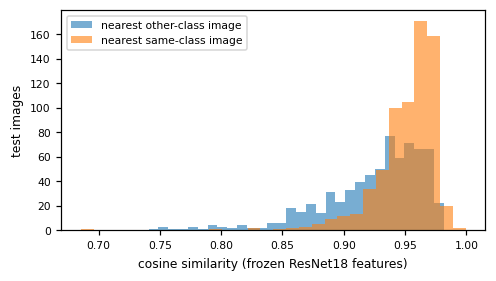

In [ ]:
def extract_features():
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1); m.fc = nn.Identity(); m.to(DEVICE).eval()
    dl = DataLoader(DIBaSDataset(range(len(df)), eval_tf), batch_size=64, shuffle=False, num_workers=0)
    feats = []
    with torch.no_grad():
        for x, _ in dl: feats.append(m(x.to(DEVICE)).float().cpu())
    return F.normalize(torch.cat(feats), dim=1).numpy()

FEATS = extract_features()
rows, same_all, other_all = [], [], []
for (rep, fold), (tr, va, te) in SPLITS.items():
    if rep != 0: continue
    pool = np.concatenate([tr, va])
    sim = FEATS[te] @ FEATS[pool].T
    same_mask = LABELS[te][:, None] == LABELS[pool][None, :]
    best_same = np.where(same_mask, sim, -1).max(1); best_other = np.where(~same_mask, sim, -1).max(1)
    nn_idx = sim.argmax(1)
    acc_nn = float((LABELS[pool][nn_idx] == LABELS[te]).mean())
    same_all.append(best_same); other_all.append(best_other)
    rows.append({"fold": fold, "1-NN accuracy on frozen ImageNet features (%)": 100 * acc_nn,
                 "median cosine sim to nearest SAME-class train image": float(np.median(best_same)),
                 "median cosine sim to nearest OTHER-class train image": float(np.median(best_other))})
NN = pd.DataFrame(rows)
NN.loc["mean"] = NN.mean(numeric_only=True)
NN.round(3).to_csv(TAB_DIR / "table_nn_leakage_audit.csv")
print(NN.round(3).to_string())

fig, ax = plt.subplots(figsize=(COL_W * 1.3, 2.6))
ax.hist(np.concatenate(other_all), bins=30, alpha=.6, label="nearest other-class image")
ax.hist(np.concatenate(same_all), bins=30, alpha=.6, label="nearest same-class image")
ax.set_xlabel("cosine similarity (frozen ResNet18 features)"); ax.set_ylabel("test images"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_nn_similarity.png"); plt.show()

## 13. Export: tables, figures, splits, config, environment

In [ ]:
(OUT / "config.json").write_text(json.dumps({k: (str(v) if isinstance(v, Path) else v) for k, v in CFG.items()}, indent=2))
(OUT / "requirements_used.txt").write_text("\n".join(f"{p}=={pkg_version(p)}" for p in
    ["torch", "torchvision", "timm", "scikit-learn", "scipy", "numpy", "pandas", "matplotlib", "thop", "grad-cam", "pillow"]))

tmp = Path("/content/_export"); shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(OUT, tmp, ignore=shutil.ignore_patterns("checkpoints"))
shutil.make_archive("/content/cnn_revision_results", "zip", tmp)
print("zipped -> /content/cnn_revision_results.zip  (also stored in", OUT, ")")
try:
    from google.colab import files
    files.download("/content/cnn_revision_results.zip")
except Exception as e:
    print("download skipped:", e)

zipped -> /content/cnn_revision_results.zip  (also stored in /content/drive/MyDrive/dibas_revision/results )


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Check these items in the manuscript (differences between the first version's text and its code)
1. **CPU latency protocol** - the first notebook timed CPU with 5 warm-up / 30 runs, the paper says 20 / 100. The new code uses 20 / 100 x 3 rounds for every setting; report the new numbers.
2. **Colour jitter** - code used saturation 0.10 (paper said 0.15 for brightness, contrast and saturation). Paper must say brightness 0.15, contrast 0.15, saturation 0.10, hue 0.02.
3. **Validation/test preprocessing** - `Resize(255)` resizes the *shorter side* to 255 (aspect ratio kept), then centre-crop 224; it is not a 255x255 resize.
4. **Pre-trained weights** - MobileNetV3-Large used `IMAGENET1K_V2`, EfficientNet-B0 and ResNet18 used `IMAGENET1K_V1`. State this, or set `CFG["mnv3_weights"] = "IMAGENET1K_V1"` and re-run for strict parity. The two newer models use ImageNet-1K-only `timm` tags.
5. **Model size** - now the serialized `state_dict` size.
6. **Disjointness check** - the first version only checked the triple intersection; now all pairs are checked and the check is stated for every fold.
7. **"Frozen" backbone in stage 1** - parameters are frozen but BatchNorm running statistics still update because the model is in train mode; for MobileNetV3 the stage-1 "head" is the whole classifier block (includes a pre-trained 960->1280 linear layer). Mention briefly.
8. **Reproducibility** - cuDNN autotuning is on, so reruns can differ in the last decimals even with fixed seeds.